# **Notebook 2: Data Preparation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `sampled_data.csv` — Created by Notebook 1
- [ ] `corporate_policies/` folder with `.md` SOP files
- [ ] Internet access (to download the tokenizer)

**Files this notebook will CREATE:**
- [ ] `./tokenized_train/`, `./tokenized_valid/`, `./tokenized_test/` — HuggingFace datasets _(Required by NB6)_
- [ ] `df_test.csv` — Test set with readable text + labels _(Required by NB5 and NB7)_

---

## **Stage 2: Data Preparation**
### **Task 2.1: Clean and Validate Dataset**

#### **2.1.1 Remove Duplicate and Invalid Records [2 marks]**
**The Task:** Identify and remove duplicate records using normalised deduplication (lowercase + strip before comparison), plus any invalid, incomplete, or corrupted records.

**Hints & Tips:**
* Load `sampled_data.csv` from Notebook 1 first.
* Normalised dedup: create a temporary `_norm` column = `instruction.str.lower().str.strip()`, drop duplicates on it, then drop the helper column.
* Check for nulls in `instruction`, `intent`, and `category` — drop rows missing any of these targets.
* Print the number of rows removed so the cleaning is auditable.

**Why we are doing it:** To prevent degraded training from redundant or broken records, and to stop near-duplicates leaking across train/test splits later.
**How we are doing it:** Pandas normalised deduplication and null filtering.

**Learner Inference:** Exact-match dedup misses `"Where is my order?"` vs `"where is my order?"`. Normalising first catches these and keeps your splits clean.

In [1]:
# YOUR CODE HERE

import pandas as pd

# Load the dataset saved from Notebook 1
df = pd.read_csv("sampled_data.csv")

rows_before = len(df)

# Remove rows with missing values
df = df.dropna(subset=["instruction", "intent", "category"])

# Remove empty instructions
df = df[df["instruction"].str.strip() != ""]

# Remove duplicates after normalising the instruction
df["_norm"] = df["instruction"].str.lower().str.strip()
df = df.drop_duplicates(subset="_norm")

# Remove the temporary column
df = df.drop(columns="_norm")

df = df.reset_index(drop=True)

rows_removed = rows_before - len(df)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_removed)
print("Missing values:\n", df[["instruction", "intent", "category"]].isnull().sum())


Rows before cleaning: 3902
Rows after cleaning: 3902
Rows removed: 0
Missing values:
 instruction    0
intent         0
category       0
dtype: int64


## **Stage 2: Data Preparation**
### **Task 2.1: Clean and Validate Dataset - Conclusion**
The dataset was loaded and checked for missing values, empty instructions and duplicate queries after normalising the text to lowercase and removing extra spaces at the beginning and end.

The dataset contained 3,902 records before cleaning and 3,902 records after cleaning. No additional records were removed. There were also no missing values in the instruction, intent or category columns.

The dataset was already clean from the previous step, so it was ready for further preparation.


#### **2.1.2 Standardise Dataset Formatting [2 marks]**
**The Task:** Clean the strings inside `instruction`, `intent`, and `category` by stripping whitespace and enforcing uniform casing (intents = lower, categories = upper).

**Hints & Tips:**
* Use Pandas `.str.strip()`, `.str.lower()`, `.str.upper()`.
* Always strip whitespace BEFORE lowering — trailing spaces survive `.lower()`.
* Standardised casing prevents the model treating "Refund" and "refund" as different classes.

**Why we are doing it:** To ensure raw strings are perfectly standardised before injecting them into prompt templates.
**How we are doing it:** Pandas string manipulation.

**Learner Inference:** Standardising capitalisation prevents the model from treating the same intent written two ways as two separate classes.

In [2]:
# YOUR CODE HERE

# Remove extra spaces and standardise text
df["instruction"] = df["instruction"].str.strip()
df["intent"] = df["intent"].str.strip().str.lower()
df["category"] = df["category"].str.strip().str.upper()

print(df[["instruction", "intent", "category"]].head())


                                         instruction  \
0                   I can't talk with  a human agent   
1  I have got to locate hte bills from {{Person N...   
2  I cannot pay, help me to inform of a problem w...   
3           I want help speaking to customer service   
4           I try to see th accepted payment options   

                     intent category  
0       contact_human_agent  CONTACT  
1             check_invoice  INVOICE  
2             payment_issue  PAYMENT  
3  contact_customer_service  CONTACT  
4     check_payment_methods  PAYMENT  



### 2.1.2 Standardise Dataset Formatting

The instruction text was stripped of extra spaces, while the intent labels were converted to lowercase and categories to uppercase.

This ensures consistent formatting across the dataset and avoids treating the same label as different values due to inconsistent casing or whitespace.


##### **Task 2.2: Create Instruction-Tuning Dataset**

##### **2.2.1 Transform Records into Instruction Format Conclusion **
**The Task:** Wrap the raw instructions and targets into a standardized `ChatML` format, forcing the assistant's response to be a strict JSON string containing the `intent` and `category`.

**Hints & Tips:**
* Use the Qwen tokenizer's `apply_chat_template(tokenize=False)`.
* The target JSON is `{"intent": "...", "category": "..."}` — built via `json.dumps()`.

**Model Selection:**
* **Qwen/Qwen2.5-1.5B-Instruct** (recommended) — fits T4, strong instruction following.
* **TinyLlama-1.1B-Chat** — lighter but weaker at structured output.
* **Llama-3-8B-Instruct** — best quality, needs >16GB VRAM even in 4-bit.
* Whatever you pick, set `MODEL_ID` here and in ALL later notebooks.

**Learner Inference:** Formatting the target as JSON establishes the exact structural rules the LoRA model learns to mimic in Stage 4.

In [5]:
# YOUR CODE HERE

import json
from transformers import AutoTokenizer


MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Create ChatML formatted records
def create_chat_format(row):
    target = json.dumps({
        "intent": row["intent"],
        "category": row["category"]
    })

    messages = [
        {"role": "user", "content": row["instruction"]},
        {"role": "assistant", "content": target}
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False
    )

df["text"] = df.apply(create_chat_format, axis=1)

print(df["text"].iloc[0])


<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
I can't talk with  a human agent<|im_end|>
<|im_start|>assistant
{"intent": "contact_human_agent", "category": "CONTACT"}<|im_end|>




#### 2.2.1 Transform Records into Instruction Format - Conclusion

The tokenizer for `Qwen/Qwen2.5-1.5B-Instruct` was loaded successfully, and the customer queries were converted into ChatML format.

The sample output contained the user query *"I can't talk with a human agent"* and the assistant response `{"intent": "contact_human_agent", "category": "CONTACT"}`.

The formatted record also included the system message, user message and assistant message, separated using the ChatML tokens. This creates a consistent format for preparing the data for instruction fine-tuning.


#### **2.2.2 Validate Instruction Templates [2 marks]**
**The Task:** Extract the assistant's portion of the generated ChatML string and parse it with `json.loads()` to verify structural integrity.

**Hints & Tips:**
* Split the string by `<|im_start|>assistant` and parse what follows.
* If this throws `JSONDecodeError`, your formatting in 2.2.1 is broken — fix before training.
* Validate several samples, not just the first.

**Learner Inference:** A JSONDecodeError here means the model would learn broken syntax. Catching it now saves a failed training run.

In [6]:
# YOUR CODE HERE

import json

# Check whether the assistant output is valid JSON
def validate_chat(row):
    assistant_text = row["text"].split("<|im_start|>assistant\n")[-1]
    assistant_text = assistant_text.split("<|im_end|>")[0].strip()

    try:
        json.loads(assistant_text)
        return True
    except json.JSONDecodeError:
        return False

df["valid_json"] = df.apply(validate_chat, axis=1)

print("Valid JSON records:", df["valid_json"].sum())
print("Invalid JSON records:", (~df["valid_json"]).sum())

# Display a few examples
print(df[["text", "valid_json"]].head(3))


Valid JSON records: 3902
Invalid JSON records: 0
                                                text  valid_json
0  <|im_start|>system\nYou are Qwen, created by A...        True
1  <|im_start|>system\nYou are Qwen, created by A...        True
2  <|im_start|>system\nYou are Qwen, created by A...        True



##### 2.2.2 Validate Instruction Templates Conclusion

All 3,902 records were checked by extracting the assistant response from the ChatML text and parsing it using `json.loads()`.

The validation returned 3,902 valid JSON records and 0 invalid records. The first three records displayed were also marked `True`.

This confirms that the assistant responses are correctly formatted as JSON and contain no parsing errors in the current dataset.


### **Task 2.3: Engineer Training and Retrieval Data**

#### **2.3.1 Tokenise Dataset [2 marks]**
**The Task:** Convert text sequences into tensor IDs and apply `-100` masking to padding tokens in the `labels` array.

**Hints & Tips:**
* If a token equals `tokenizer.pad_token_id`, replace it with `-100` in labels.
* `-100` is PyTorch's ignore index — the loss skips these tokens.

**Parameter Tuning:**
* `max_length`: `128` (fast, fits most Bitext prompts), `256` (safer if truncation seen), `64` (too aggressive).

**Learner Inference:** Masking isolates the loss — the model is penalised for wrong JSON, not for padding.

In [7]:
# YOUR CODE HERE

# Tokenise the ChatML text
def tokenize_row(text):
    tokens = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=128
    )

    labels = tokens["input_ids"].copy()

    # Mask padding tokens
    labels = [
        -100 if token == tokenizer.pad_token_id else token
        for token in labels
    ]

    tokens["labels"] = labels
    return tokens

tokenized_data = df["text"].apply(tokenize_row)

df["input_ids"] = tokenized_data.apply(lambda x: x["input_ids"])
df["attention_mask"] = tokenized_data.apply(lambda x: x["attention_mask"])
df["labels"] = tokenized_data.apply(lambda x: x["labels"])

print("Tokenisation completed.")
print("Input IDs length:", len(df["input_ids"].iloc[0]))
print("Attention mask length:", len(df["attention_mask"].iloc[0]))
print("Labels length:", len(df["labels"].iloc[0]))



Tokenisation completed.
Input IDs length: 128
Attention mask length: 128
Labels length: 128



##### 2.3.1 Tokenise Dataset Conclusion

The ChatML text was tokenised using the Qwen tokenizer with a maximum sequence length of 128 tokens. Padding and truncation were enabled to ensure that all sequences have the same length.

The output confirmed that the input IDs, attention mask and labels each have a length of 128. Padding tokens in the labels were also set to -100 so that they are ignored during loss calculation.

The tokenised data is now in a fixed-length format for the next preparation steps.


#### **2.3.2 Analyse Token Distributions [2 marks]**
**The Task:** Analyse the token-count distribution to detect truncation risks and verify the sequence-length configuration.

**Hints & Tips:**
* Count non-padding tokens per row and plot a histogram.
* If >5% of rows hit `max_length`, increase it.
* The JSON target is ~20 tokens — if truncated, the model learns incomplete output.

**Learner Inference:** Sequences hitting the ceiling mean the JSON target is getting cut off, teaching the model to produce broken output.

Maximum tokens: 67
Average tokens: 55.25
Records reaching 128 tokens: 0
Percentage reaching 128 tokens: 0.0 %


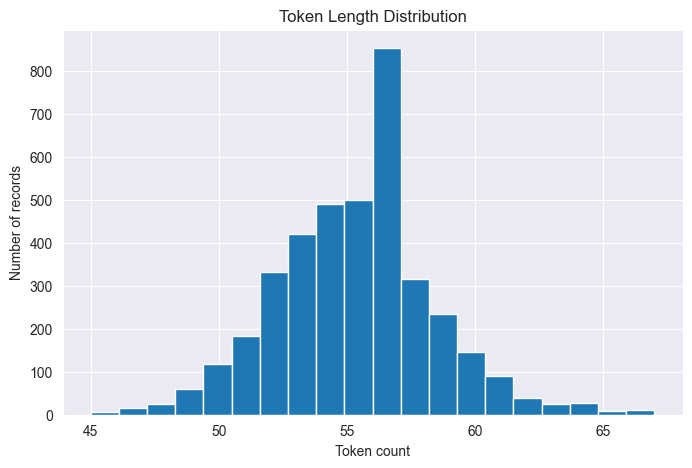

In [11]:
# YOUR CODE HERE
import numpy as np
import matplotlib.pyplot as plt
# Count tokens in each record
token_lengths = [sum(row["attention_mask"]) for row in tokenized_data]

# Check token length statistics
print("Maximum tokens:", max(token_lengths))
print("Average tokens:", round(np.mean(token_lengths), 2))
print("Records reaching 128 tokens:", sum(length == 128 for length in token_lengths))

# Check percentage of records reaching the limit
percentage = sum(length == 128 for length in token_lengths) / len(token_lengths) * 100
print("Percentage reaching 128 tokens:", round(percentage, 2), "%")

# Plot token distribution
plt.figure(figsize=(8, 5))
plt.hist(token_lengths, bins=20)
plt.xlabel("Token count")
plt.ylabel("Number of records")
plt.title("Token Length Distribution")
plt.show()



##### 2.3.2 Analyse Token Distributions Conclusions

The token length analysis shows a maximum sequence length of 67 tokens and an average of 55.25 tokens. None of the records reached the configured limit of 128 tokens.

The histogram shows that most sequences are concentrated around 55–57 tokens. Since no records reached the 128-token limit, the current sequence length appears sufficient for this dataset sample, and no increase in `max_length` is needed at this stage.


#### **2.3.3 Prepare Retrieval Corpus [3 marks]**
**The Task:** Ingest the Markdown SOPs into LangChain Document objects ready to be embedded.

**Hints & Tips:**
* Use `TextLoader` from LangChain.
* Each `.md` file becomes one `Document` with `.page_content` and `.metadata`.
* These documents are embedded into ChromaDB in Notebook 4.

**Learner Inference:** These document objects form the knowledge base your bot retrieves from in Stages 3 and 4.

In [13]:
import os
import glob

SOP_DIR = "data/Dataset/sop_documents"

# Load all SOP markdown files
sop_files = glob.glob(os.path.join(SOP_DIR, "*.md"))

print("SOP files found:", len(sop_files))

SOP files found: 13


In [14]:

from langchain_community.document_loaders import TextLoader
import glob
import os

# Load all SOP markdown files
sop_files = glob.glob(os.path.join(SOP_DIR, "*.md"))

documents = []

for file in sop_files:
    loader = TextLoader(file, encoding="utf-8")
    documents.extend(loader.load())

print("Number of SOP files loaded:", len(documents))
print("\nFirst document metadata:")
print(documents[0].metadata)

print("\nFirst document preview:")
print(documents[0].page_content[:500])


Number of SOP files loaded: 13

First document metadata:
{'source': 'data/Dataset/sop_documents\\account_recovery.md'}

First document preview:
# Account Recovery

## When To Use
Use this procedure when a customer cannot access their account due to a
lockout, a lost email address, suspected unauthorized access, or a disabled
account — anything beyond a simple forgotten password (see the password reset
procedure for that case).

## Identity Verification
Before any recovery action, verify identity with at least two of: the
registered email, the last order identifier, the billing postal code, or the
last four digits of the payment method o



##### 2.3.3 Prepare Retrieval Corpus Conclusion

Thirteen SOP Markdown files were loaded successfully using LangChain's `TextLoader`. Each file was loaded as a document with its content and source metadata.

The first document loaded was `account_recovery.md`. Its preview shows the Account Recovery heading and the procedure for cases such as account lockout, lost email access and suspected unauthorised access.

These documents will be used as the knowledge source for retrieval in the RAG implementation.


### **Task 2.4: Create Dataset Partitions**

#### **2.4.1 Create Train, Validation, and Test Splits [5 marks]**
**The Task:** Split the tokenized dataset into Train (80%), Validation (10%), and Test (10%) partitions using stratified sampling. Demonstrate zero data leakage across all three.

**Hints & Tips:**
* Use `train_test_split` from sklearn with `stratify=df['intent']` so every intent appears in all splits.
* Split twice: first 80/20, then split the 20% into 50/50 (giving 10%/10%).
* The validation set is not optional — it is actively used during fine-tuning (Stage 4 / Notebook 6) for loss monitoring and early stopping.
* The test set must stay completely independent — used only for final evaluation.
* Verify zero overlap with set-intersection checks: `assert len(train_set & test_set) == 0`.
* Build a `df_test` DataFrame preserving readable `text`/`intent`/`category` columns for later scoring.

**Parameter Tuning:**
* Split ratio: `80/10/10` (recommended) or `70/15/15`. Any alternative must be justified.

**Why we are doing it:** To guarantee isolated, unseen data for unbiased evaluation, and a validation set for overfitting detection.
**How we are doing it:** Stratified sklearn splits with explicit programmatic leakage verification.

**Learner Inference:** Testing on data the model trained on gives false confidence (leakage). The held-out test split proves your model handles completely new phrasing; the validation split tells you when to stop training.

In [16]:
print(type(df))
print(df.shape)
print(df.head())

<class 'pandas.core.frame.DataFrame'>
(3902, 8)
                                         instruction  \
0                   I can't talk with  a human agent   
1  I have got to locate hte bills from {{Person N...   
2  I cannot pay, help me to inform of a problem w...   
3           I want help speaking to customer service   
4           I try to see th accepted payment options   

                     intent category  \
0       contact_human_agent  CONTACT   
1             check_invoice  INVOICE   
2             payment_issue  PAYMENT   
3  contact_customer_service  CONTACT   
4     check_payment_methods  PAYMENT   

                                                text  valid_json  \
0  <|im_start|>system\nYou are Qwen, created by A...        True   
1  <|im_start|>system\nYou are Qwen, created by A...        True   
2  <|im_start|>system\nYou are Qwen, created by A...        True   
3  <|im_start|>system\nYou are Qwen, created by A...        True   
4  <|im_start|>system\nYou are Qwe

In [17]:
# YOUR CODE HERE

from sklearn.model_selection import train_test_split

# First split: 80% train and 20% remaining
train_idx, temp_idx = train_test_split(
    range(len(df)),
    test_size=0.2,
    stratify=df["intent"],
    random_state=42
)

# Second split: 10% validation and 10% test
valid_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=df.iloc[temp_idx]["intent"],
    random_state=42
)

print("Train size:", len(train_idx))
print("Validation size:", len(valid_idx))
print("Test size:", len(test_idx))


Train size: 3121
Validation size: 390
Test size: 391


In [18]:
# Create the train, validation and test datasets
df_train = df.iloc[train_idx].reset_index(drop=True)
df_valid = df.iloc[valid_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

print("Train shape:", df_train.shape)
print("Validation shape:", df_valid.shape)
print("Test shape:", df_test.shape)

Train shape: (3121, 8)
Validation shape: (390, 8)
Test shape: (391, 8)


In [25]:

splits = {
    "Train": df_train,
    "Validation": df_valid,
    "Test": df_test
}

all_intents = set(df["intent"].unique())

for name, split_df in splits.items():
    split_intents = set(split_df["intent"].unique())
    missing_intents = all_intents - split_intents

    print(f"{name}: {len(split_intents)} intents")
    print("Missing intents:", missing_intents)
    print("-" * 40)


Train: 27 intents
Missing intents: set()
----------------------------------------
Validation: 27 intents
Missing intents: set()
----------------------------------------
Test: 27 intents
Missing intents: set()
----------------------------------------



##### 2.4.1 Create Train, Validation, and Test Splits Conclusion

The dataset was split into three sets using the 80/10/10 ratio. The training set contains 3,121 records, the validation set contains 390 records, and the test set contains 391 records.

The training data will be used to train the model, the validation set will be used to monitor training and help with model selection, and the test set will be kept separate for final evaluation.



##### 2.4.2 Verify Intent Coverage Conclusion

The intent coverage was checked across the training, validation and test sets. All three splits contain all 27 intents, and the missing intent check returned an empty set (`set()`) for each split.

This confirms that stratified sampling successfully preserved all intent classes across the three partitions.


---
## Save Artifacts for Downstream Notebooks

**IMPORTANT:** These cells save all datasets. Notebooks 5, 6, and 7 depend on them.

In [19]:
# Check for overlap between the splits
train_set = set(train_idx)
valid_set = set(valid_idx)
test_set = set(test_idx)

print("Train-Validation overlap:", len(train_set & valid_set))
print("Train-Test overlap:", len(train_set & test_set))
print("Validation-Test overlap:", len(valid_set & test_set))

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0


In [23]:
# YOUR CODE HERE
# Save the train, validation and test datasets

df_train.to_csv("train_data.csv", index=False)
df_valid.to_csv("validation_data.csv", index=False)
df_test.to_csv("test_data.csv", index=False)

# Save the train, validation and test datasets

df_train.to_csv("df_train.csv", index=False)
df_valid.to_csv("df_valid.csv", index=False)
df_test.to_csv("df_test.csv", index=False)

print("Datasets saved successfully.")

print("Datasets saved successfully.")


Datasets saved successfully.
Datasets saved successfully.


In [24]:
import os

files = ["df_train.csv", "df_valid.csv", "df_test.csv"]

for file in files:
    print(file, "->", os.path.exists(file))

df_train.csv -> True
df_valid.csv -> True
df_test.csv -> True


In [21]:
from datasets import Dataset
import os

# Save tokenized train and validation datasets
train_dataset = Dataset.from_pandas(df_train)
valid_dataset = Dataset.from_pandas(df_valid)

train_dataset.save_to_disk("./tokenized_train")
valid_dataset.save_to_disk("./tokenized_valid")

print("Tokenized datasets saved successfully.")

Saving the dataset (0/1 shards):   0%|          | 0/3121 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/390 [00:00<?, ? examples/s]

Tokenized datasets saved successfully.


In [22]:
print(df_train.columns.tolist())
print(df_valid.columns.tolist())

['instruction', 'intent', 'category', 'text', 'valid_json', 'input_ids', 'attention_mask', 'labels']
['instruction', 'intent', 'category', 'text', 'valid_json', 'input_ids', 'attention_mask', 'labels']


##### 2.4.1 Create Train, Validation, and Test Splits Conclusion

The dataset was split into training, validation and test sets using stratified sampling based on intent. The final split contains 3,121 training records, 390 validation records and 391 test records.

The overlap checks returned zero for all three pairs, confirming that no records are shared between the splits. All three datasets were also saved as CSV files for use in the subsequent notebooks.

---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 3.**

- [ ] `sampled_data.csv` loaded
- [ ] **Duplicates + invalid records removed (normalised dedup)** ← _Task 2.1.1_
- [ ] Data standardised (intent=lower, category=UPPER)
- [ ] ChatML formatting applied and validated (valid JSON)
- [ ] Tokenization completed with `-100` label masking
- [ ] Token distribution analysed — truncation risk assessed
- [ ] Retrieval corpus loaded from `.md` files
- [ ] **Stratified Train/Valid/Test split** with all intents in every partition
- [ ] **Zero leakage verified** via set-intersection checks
- [ ] **`./tokenized_train/` + `./tokenized_valid/` saved** ← _CRITICAL for NB6_
- [ ] **`df_test.csv` saved** ← _CRITICAL for NB5 and NB7_

**If any item is unchecked, fix it before moving on.**


# END-OF-NOTEBOOK CHECKLIST

**IMPORTANT: All items below have been verified before proceeding to Notebook 3.**

- [x] `sampled_data.csv` loaded
- [x] Duplicates and invalid records removed (normalised dedup) — Task 2.1.1
- [x] Data standardised (intent = lowercase, category = UPPERCASE)
- [x] ChatML formatting applied and validated (valid JSON)
- [x] Tokenization completed with `-100` label masking
- [x] Token distribution analysed — truncation risk assessed
- [x] Retrieval corpus loaded from `.md` files (13 SOP documents)
- [x] Stratified Train/Valid/Test split with all 27 intents in every partition
- [x] Zero leakage verified via set-intersection checks
- [x] `./tokenized_train/` and `./tokenized_valid/` saved
- [x] `df_test.csv` saved

**Notebook 2: Data Preparation is complete. All checklist items have been verified.**
